# Лабораторна робота №4 — Основи штучного інтелекту

**Варіант №9 · Методи кластеризації · Приклад №19 та задача №8**

**Завдання з LMS:** ознайомитися з методами кластеризації, розглянути приклад №19 із методичних вказівок і розв'язати задачу №8 за своїм варіантом. Для оцінювання якості використати заздалегідь відомі мітки `y`.

**Параметри варіанта №9:** `a = 1`, `b = 2`, `c = 0`, `d = 3`, стандартне відхилення `s = 0.5`.

**Мета:** реалізувати K-Means, AgglomerativeClustering і DBSCAN; візуалізувати розбиття на кластери; порівняти результати зі справжніми класами за метрикою Adjusted Rand Index; виконати прогноз нової точки методом K-Means.

Методичне джерело: Копей В. Б., Онисько О. Р. *Основи штучного інтелекту: лабораторний практикум*, 2024, с. 42–44, 55, 57. Код адаптовано до Python 3.11 та актуального scikit-learn.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import adjusted_rand_score, silhouette_score

A, B, C, D = 1, 2, 0, 3
SEED = 9
OUT = Path('results')
OUT.mkdir(exist_ok=True)
plt.rcParams['figure.dpi'] = 115
plt.rcParams['font.family'] = 'DejaVu Sans'
print(f'Python / scikit-learn: {sklearn.__version__}')
print(f'Варіант 9: a={A}, b={B}, c={C}, d={D}; seed={SEED}')

def finish(filename):
    plt.tight_layout()
    plt.savefig(OUT / filename, dpi=170, bbox_inches='tight')
    plt.show()
    plt.close()
    print('Збережено:', OUT / filename)

def plot_classes(X, labels, title, filename, centers=None, new_point=None):
    fig, ax = plt.subplots(figsize=(7.0, 4.8))
    for cluster_id in sorted(set(labels)):
        rows = X[np.asarray(labels) == cluster_id]
        caption = 'Шум (-1)' if cluster_id == -1 else f'Мітка {cluster_id}'
        ax.scatter(rows[:, 0], rows[:, 1], s=65, edgecolor='black', linewidth=0.35, label=caption)
    if centers is not None:
        ax.scatter(centers[:, 0], centers[:, 1], c='black', marker='X', s=180, label='Центри кластерів')
    if new_point is not None:
        ax.scatter(new_point[0], new_point[1], c='red', marker='*', s=260, label='Нова точка')
    ax.set(xlabel='x0', ylabel='x1', title=title)
    ax.axis('equal')
    ax.grid(alpha=0.25)
    ax.legend(fontsize=9)
    finish(filename)

Python / scikit-learn: 1.9.1
Варіант 9: a=1, b=2, c=0, d=3; seed=9


## 1. Теоретичні відомості

**Кластеризація** — навчання без учителя: алгоритм групує близькі об'єкти, не використовуючи відомі мітки для підгонки.

- **K-Means** шукає задану кількість центрів кластерів та відносить точки до найближчого центру. Має метод `predict` для нових точок.
- **AgglomerativeClustering** послідовно об'єднує подібні групи; метод `fit_predict` повертає мітки, але звичайний `predict` у цій реалізації відсутній.
- **DBSCAN** об'єднує сусідні щільні області; точки, не віднесені до кластерів, отримують мітку `-1` (шум). Метод `predict` також відсутній.
- **Adjusted Rand Index (ARI)** порівнює два розбиття з поправкою на випадкову згоду. Значення `1` відповідає повному збігу кластерів зі справжніми мітками, а значення близько `0` — випадковому збігу. Нумерація кластерів не впливає на ARI.

Мітки `y` **не передаємо у `.fit()`**: вони потрібні тільки для перевірки якості.

## 2. Приклад №19 із методички

Відтворимо 20 точок із методичних вказівок і розглянемо три методи кластеризації. Перші 10 об'єктів належать до початкового класу `0`, решта 10 — до класу `1`.

Форма X: (20, 2) ; форма y: (20,)


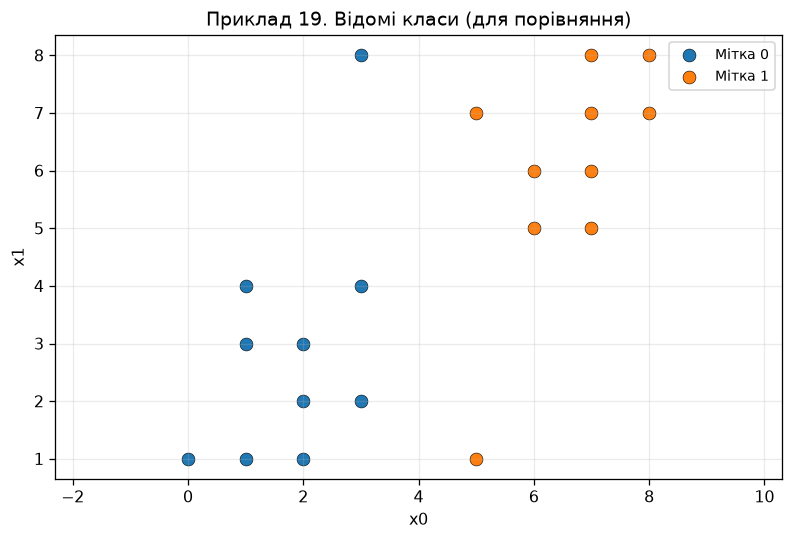

Збережено: results\01_ex19_true_classes.png


In [2]:
X_ex = np.array([
    [0,1,1,2,2,3,2,3,1,3, 6,5,6,7,7,8,7,7,8,5],
    [1,1,3,1,2,2,3,4,4,8, 5,7,6,7,6,7,5,8,8,1]
], dtype=float).T
y_ex = np.array([0]*10 + [1]*10)
print('Форма X:', X_ex.shape, '; форма y:', y_ex.shape)
plot_classes(X_ex, y_ex, 'Приклад 19. Відомі класи (для порівняння)', '01_ex19_true_classes.png')


K-Means:
Мітки кластерів: [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0]
Центри: [[2.0, 2.2], [6.4, 6.7]]
Прогноз для [1, 2]: 0
ARI: 0.62


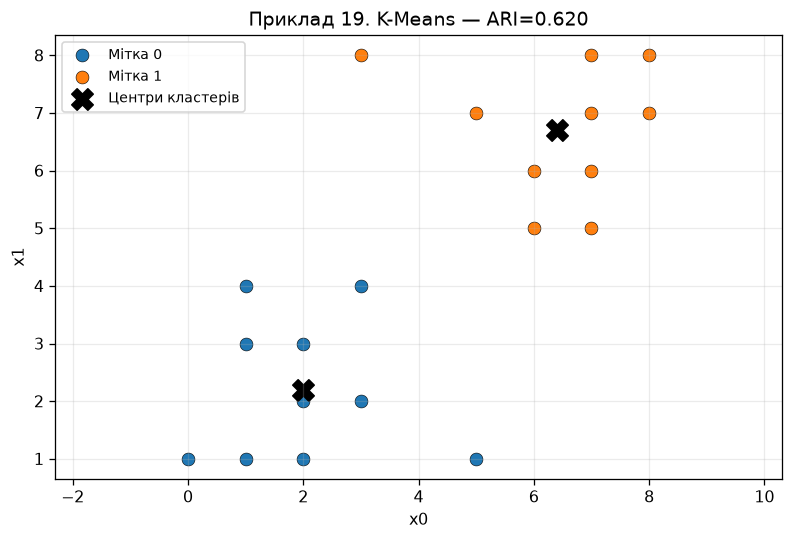

Збережено: results\02_ex19_k-means.png

Agglomerative:
Мітки кластерів: [1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1]
ARI: 0.62


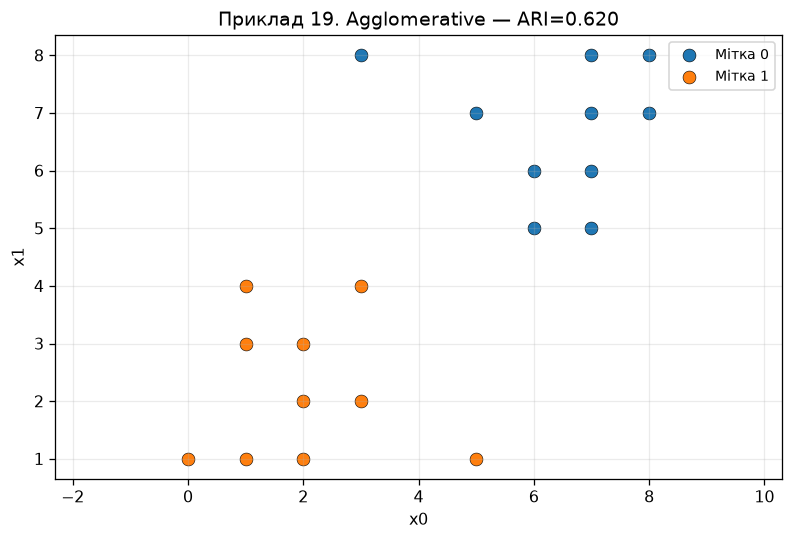

Збережено: results\03_ex19_agglomerative.png

DBSCAN:
Мітки кластерів: [0, 0, 0, 0, 0, 0, 0, 0, 0, -1, 1, 1, 1, 1, 1, 1, 1, 1, 1, -1]
ARI: 0.79753


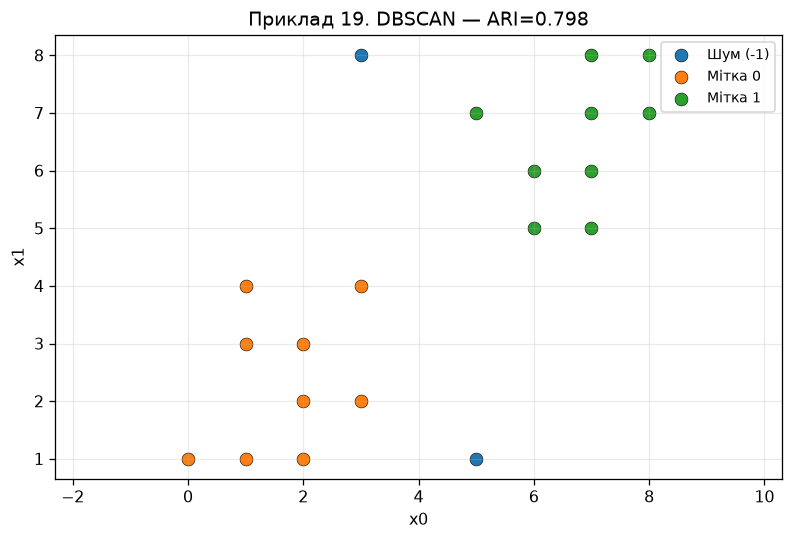

Збережено: results\04_ex19_dbscan.png


,Модель,ARI,Кількість кластерів,Шумові точки
0,K-Means,0.620000,2,0
1,Agglomerative,0.620000,2,0
2,DBSCAN,0.797532,2,2


In [3]:
ex_models = {
    'K-Means': KMeans(n_clusters=2, n_init=10, random_state=SEED),
    'Agglomerative': AgglomerativeClustering(n_clusters=2, linkage='ward'),
    'DBSCAN': DBSCAN(eps=2.0, min_samples=5),
}
ex_data = []
for i, (name, model) in enumerate(ex_models.items(), start=2):
    predicted = model.fit_predict(X_ex)
    ari = adjusted_rand_score(y_ex, predicted)
    ex_data.append({'Модель': name, 'ARI': ari, 'Кількість кластерів': len(set(predicted) - {-1}),
                    'Шумові точки': int(np.sum(predicted == -1))})
    print(f'\n{name}:')
    print('Мітки кластерів:', predicted.tolist())
    if name == 'K-Means':
        print('Центри:', np.round(model.cluster_centers_, 3).tolist())
        print('Прогноз для [1, 2]:', int(model.predict([[1, 2]])[0]))
    print('ARI:', round(ari, 5))
    plot_classes(X_ex, predicted, f'Приклад 19. {name} — ARI={ari:.3f}',
                 f'{i:02d}_ex19_{name.lower()}.png',
                 centers=model.cluster_centers_ if name == 'K-Means' else None)
ex_table = pd.DataFrame(ex_data)
display(ex_table)
ex_table.to_csv(OUT / 'example19_metrics.csv', index=False, encoding='utf-8-sig')

**Аналіз прикладу №19.** Можливі перестановки міток `0` і `1` не є помилкою кластеризації. DBSCAN може позначити деякі об'єкти як шум (`-1`). Якість усіх трьох алгоритмів порівнюємо за ARI.

## 3. Задача №8 — варіант №9

За методичкою генеруємо дві ознаки для 20 об'єктів:

\[
\begin{aligned}
x_0&=[\mathcal{N}(a,s),\ldots\ (10);\ \mathcal{N}(b,s),\ldots\ (10)],\\
x_1&=[\mathcal{N}(c,s),\ldots\ (10);\ \mathcal{N}(d,s),\ldots\ (10)].
\end{aligned}
\]

Для варіанта №9 маємо центри приблизно `(1; 0)` та `(2; 3)` і `s=0.5`. Щоб можна було повторити експеримент, використовуємо `seed=9`. Масив справжніх міток `y` містить 10 нулів і 10 одиниць, як пропонує LMS.

,x0,x1,Відома мітка y
0,0.599,-0.199,0
1,1.121,0.093,0
2,0.172,-0.761,0
3,1.328,1.172,0
4,1.572,-0.047,0
5,0.774,-0.193,0
6,1.215,0.405,0
7,1.125,-0.446,0
8,0.803,0.384,0
9,0.569,-0.586,0


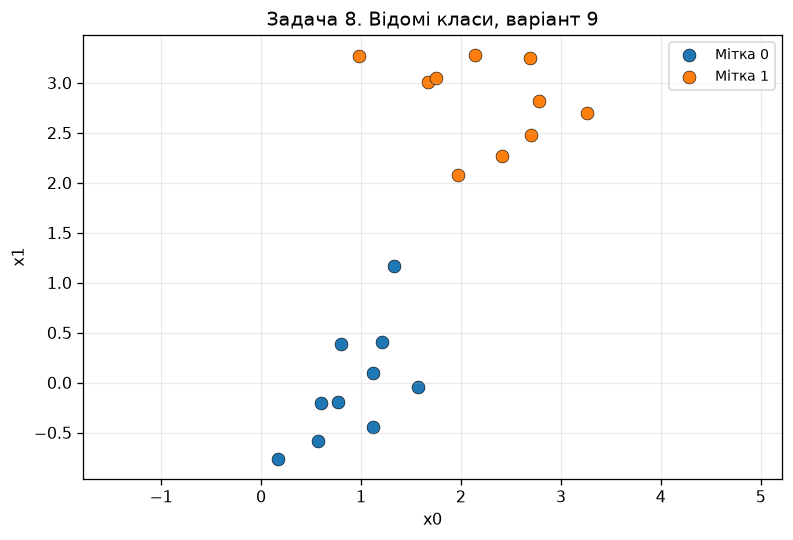

Збережено: results\05_task08_true_classes.png


In [4]:
rng = np.random.default_rng(SEED)
s = 0.5
x0 = np.hstack([rng.normal(A, s, 10), rng.normal(B, s, 10)])
x1 = np.hstack([rng.normal(C, s, 10), rng.normal(D, s, 10)])
X = np.vstack([x0, x1]).T  # 20 рядків-об'єктів, 2 стовпці-ознаки
y = np.array([0,0,0,0,0,0,0,0,0,0, 1,1,1,1,1,1,1,1,1,1])
assert X.shape == (20, 2) and y.shape == (20,)
points_df = pd.DataFrame({'x0': X[:,0], 'x1': X[:,1], 'Відома мітка y': y})
display(points_df.round(3))
points_df.to_csv(OUT / 'task08_points.csv', index=False, encoding='utf-8-sig')
plot_classes(X, y, 'Задача 8. Відомі класи, варіант 9', '05_task08_true_classes.png')

## 4. Кластеризація згенерованих даних

Налаштування відповідають двом очікуваним групам. Для DBSCAN параметри `eps=0.9`, `min_samples=3` підібрано як параметри експерименту; на інших вибірках вони можуть потребувати коригування.

K-Means: кластерні мітки = [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]; ARI = 1.0000
Центри K-Means: [[0.9278, -0.0178], [2.2378, 2.8214]]


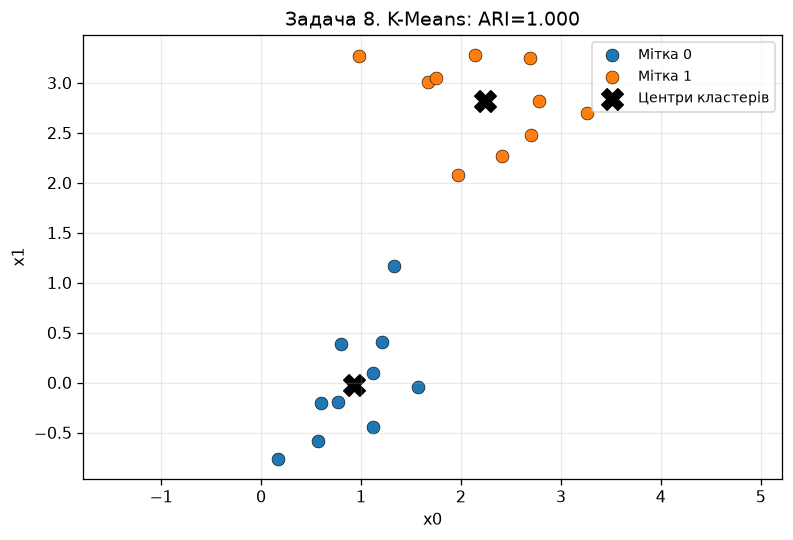

Збережено: results\06_task08_k-means.png
Agglomerative: кластерні мітки = [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]; ARI = 1.0000


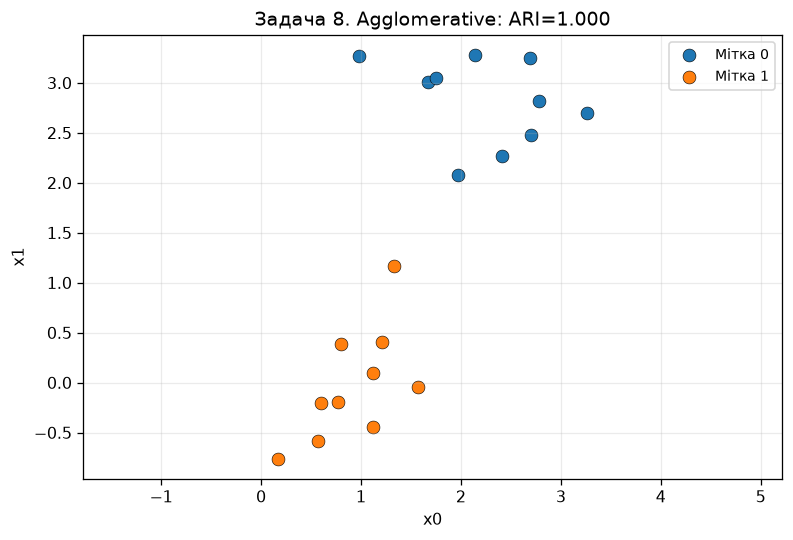

Збережено: results\07_task08_agglomerative.png
DBSCAN: кластерні мітки = [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]; ARI = 1.0000


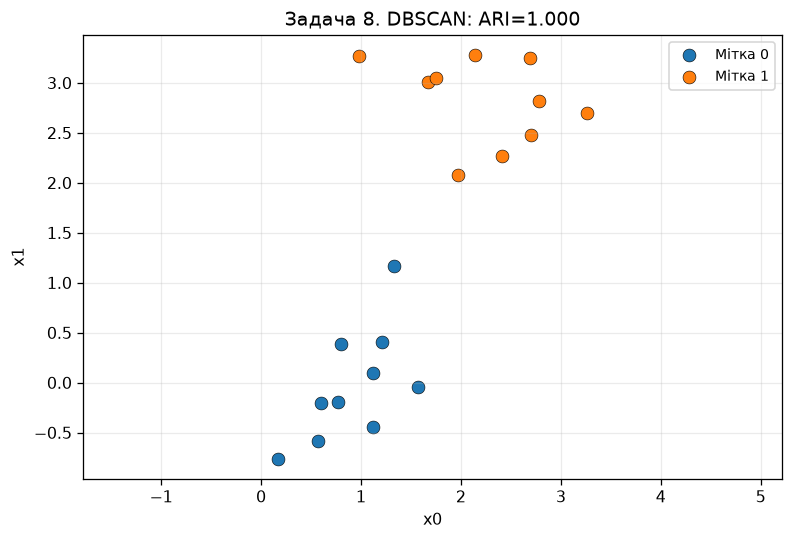

Збережено: results\08_task08_dbscan.png


,Модель,ARI,Кластерів,Шумових точок
0,K-Means,1.0,2,0
1,Agglomerative,1.0,2,0
2,DBSCAN,1.0,2,0


In [5]:
task_models = {
    'K-Means': KMeans(n_clusters=2, n_init=10, random_state=SEED),
    'Agglomerative': AgglomerativeClustering(n_clusters=2, linkage='ward'),
    'DBSCAN': DBSCAN(eps=0.9, min_samples=3),
}
task_rows = []
for j, (name, model) in enumerate(task_models.items(), start=6):
    cluster_labels = model.fit_predict(X)
    ari = adjusted_rand_score(y, cluster_labels)
    n_clusters = len(set(cluster_labels) - {-1})
    noise_count = int(np.sum(cluster_labels == -1))
    task_rows.append({'Модель': name, 'ARI': ari, 'Кластерів': n_clusters, 'Шумових точок': noise_count})
    print(f'{name}: кластерні мітки = {cluster_labels.tolist()}; ARI = {ari:.4f}')
    if name == 'K-Means':
        print('Центри K-Means:', np.round(model.cluster_centers_, 4).tolist())
    plot_classes(X, cluster_labels, f'Задача 8. {name}: ARI={ari:.3f}',
                 f'{j:02d}_task08_{name.lower()}.png',
                 centers=model.cluster_centers_ if name == 'K-Means' else None)
comparison = pd.DataFrame(task_rows).sort_values('ARI', ascending=False).reset_index(drop=True)
display(comparison)
comparison.to_csv(OUT / 'task08_metrics.csv', index=False, encoding='utf-8-sig')

## 5. Прогноз для нової точки

Вимога задачі: виконати прогноз для довільної нової точки. Використаємо K-Means, оскільки ця модель підтримує `predict`. Важливо: передбачена цифра — **номер кластера**, а не обов'язково вихідна мітка з масиву `y`.

Нова точка: [1.2, 0.2]
Прогнозований номер кластера K-Means: 0
Центр прогнозованого кластера: [0.9278, -0.0178]


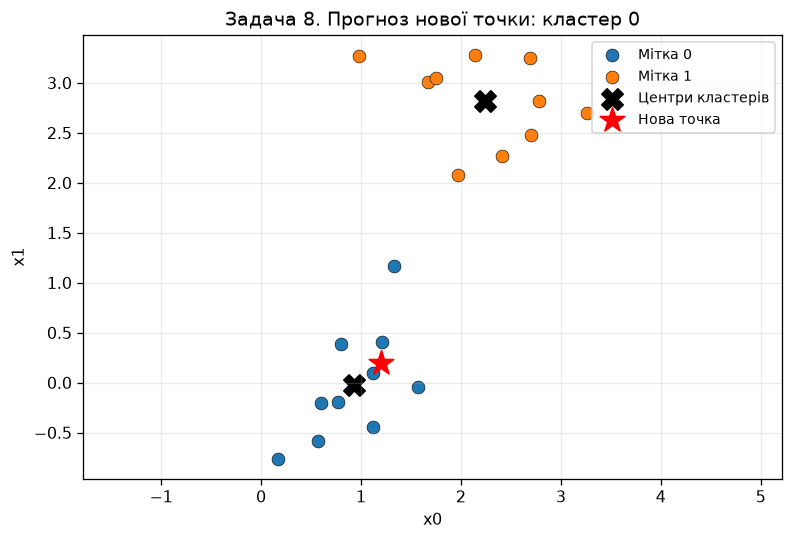

Збережено: results\09_task08_prediction.png


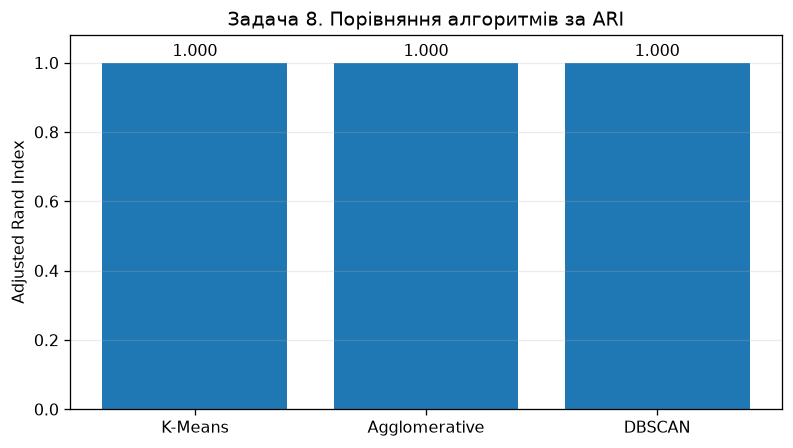

Збережено: results\10_task08_ari_comparison.png


In [6]:
km = task_models['K-Means']
new_point = np.array([[1.2, 0.2]])
cluster_id = int(km.predict(new_point)[0])
print('Нова точка:', new_point[0].tolist())
print('Прогнозований номер кластера K-Means:', cluster_id)
print('Центр прогнозованого кластера:', np.round(km.cluster_centers_[cluster_id], 4).tolist())
plot_classes(X, km.labels_,
             f'Задача 8. Прогноз нової точки: кластер {cluster_id}',
             '09_task08_prediction.png', centers=km.cluster_centers_, new_point=new_point[0])
fig, ax = plt.subplots(figsize=(7,4))
ax.bar(comparison['Модель'], comparison['ARI'])
ax.set(title='Задача 8. Порівняння алгоритмів за ARI', ylabel='Adjusted Rand Index', ylim=(0, 1.08))
for i, val in enumerate(comparison['ARI']): ax.text(i, val+0.02, f'{val:.3f}', ha='center')
ax.grid(axis='y', alpha=.25)
finish('10_task08_ari_comparison.png')

## 6. ВИСНОВОК

У лабораторній роботі досліджено методи кластеризації K-Means, AgglomerativeClustering і DBSCAN на даних прикладу №19 та задачі №8. Для варіанта №9 згенеровано 20 двовимірних точок і побудовано їх кластеризацію.

Для порівняння алгоритмів використано метрику ARI за відомими мітками класів. Окремо виконано прогноз належності нової точки до кластера методом K-Means. У процесі виконання досліджено відмінності між підходами до кластеризації та особливості інтерпретації номерів отриманих кластерів.
